# 02 - LLM Feature Engineering & EDA

**Author:** Member 2 (Adam Harith) | **Date:** 24 Nov 2026

**Contents:**
1. Data loading & quality checks
2. Exploratory Data Analysis (EDA)
3. LLM/SLM feature extraction from `customer_feedback`
4. Shared preprocessing pipeline

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
FIG_DIR = "../figures/"

df = pd.read_csv("../data/processed/loan_data.csv")
print(df.shape)
df.head()

(1200, 13)


,customer_id,age,annual_income,loan_amount,loan_term_months,credit_score,existing_debts,employment_years,employment_type,region,loan_purpose,customer_feedback,default
0,C0001,24,53500,46500,84,790,93200,0,Salaried,Penang,Personal,"Things are okay, just a bit stretched compared...",0
1,C0002,38,53000,81500,72,711,132700,5,Contract,Klang Valley,Car,Every ringgit is already spoken for by the tim...,1
2,C0003,49,63500,75000,84,504,27900,18,Salaried,Klang Valley,Car,I've asked family for small help once or twice...,0
3,C0004,65,147000,109000,60,547,79400,7,Contract,Sarawak,Car,"I'm begging for some flexibility on the RM2,36...",1
4,C0005,21,54500,56500,72,693,35800,0,Contract,Klang Valley,Education,I'd call my situation tight but under control....,0


## 1. Data Quality Checks

In [3]:
print("Data types:\n", df.dtypes, "\n")
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate customer_id:", df["customer_id"].duplicated().sum())
print("Duplicate feedback text:", df["customer_feedback"].duplicated().sum())

Data types:
 customer_id            str
age                  int64
annual_income        int64
loan_amount          int64
loan_term_months     int64
credit_score         int64
existing_debts       int64
employment_years     int64
employment_type        str
region                 str
loan_purpose           str
customer_feedback      str
default              int64
dtype: object 

Missing values per column:
 customer_id          0
age                  0
annual_income        0
loan_amount          0
loan_term_months     0
credit_score         0
existing_debts       0
employment_years     0
employment_type      0
region               0
loan_purpose         0
customer_feedback    0
default              0
dtype: int64 

Duplicate customer_id: 0
Duplicate feedback text: 0


In [4]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,1200.0,43.2,13.1,21.0,32.0,43.0,55.0,65.0
annual_income,1200.0,76898.8,44308.2,24000.0,45000.0,66000.0,95625.0,300000.0
loan_amount,1200.0,119106.7,120822.0,5000.0,28500.0,71250.0,176625.0,500000.0
loan_term_months,1200.0,121.5,104.7,12.0,48.0,72.0,120.0,360.0
credit_score,1200.0,661.0,83.8,384.0,603.0,660.0,719.2,850.0
existing_debts,1200.0,38002.0,42542.4,0.0,9950.0,24900.0,50825.0,200000.0
employment_years,1200.0,7.7,7.8,0.0,2.0,5.0,12.0,36.0
default,1200.0,0.2,0.4,0.0,0.0,0.0,0.0,1.0


In [5]:
df["feedback_words"] = df["customer_feedback"].str.split().str.len()
print(df["feedback_words"].describe())
df[["customer_feedback", "default"]].sample(5, random_state=42)

count    1200.000000
mean       18.640000
std         8.153781
min         6.000000
25%        12.000000
50%        16.000000
75%        24.000000
max        44.000000
Name: feedback_words, dtype: float64


,customer_feedback,default
1178,I'm proud of how well I've managed my finances...,0
865,"My pay arrives early in the month, so I settle...",0
101,I'm trimming subscriptions and dining out to k...,1
439,"I can pay RM1,310 each month and still save a ...",0
58,We still manage to save a little every month a...,1


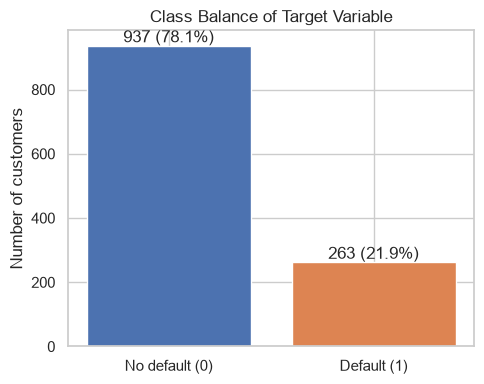

In [6]:
counts = df["default"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["No default (0)", "Default (1)"], counts.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, f"{v} ({v/len(df):.1%})", ha="center")
ax.set_title("Class Balance of Target Variable")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.savefig(FIG_DIR + "class_balance.png", dpi=150)
plt.show()

**Observation:** The dataset has 1,200 records and 13 columns with no missing values
or duplicates. The target is moderately imbalanced (~22% default), so we will use a
stratified train/test split and focus on F1-score and ROC-AUC rather than accuracy alone.